In [1]:
# Analysis of QAQC results

In [2]:
# Import modules
import numpy as np
import netCDF4 as nc
import xarray as xr
import sys, os
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
import datetime
import timeit
import glob


In [3]:
# User inputs

input_dataset = 'CCAM' # 'BARRA' 'BARPA' 'CCAM'
data_type = 'raw'

set_SSP = 'historical' # historical  ssp126  ssp370
set_model = 'NorESM2-MM'
# BARPA models - ACCESS-CM2  ACCESS-ESM1-5  CESM2  CMCC-ESM2  EC-Earth3  NorESM2-MM  MPI-ESM1-2-HR  ERA5
# CCAM models  - ACCESS-CM2  ACCESS-ESM1-5  CESM2  CMCC-ESM2  EC-Earth3  NorESM2-MM  CNRM-ESM2-1
# set_SSP and set_model will be ignored if input_dataset == 'BARRA'

crop_to_aust_region = 'yes'
mask_ocean = 'yes'
mask_nonaust_land = 'yes'

dir_in = '/g/data/eg3/cdr565/code_output/'

set_var = 'wbgt_t_diff_wind' # 'wbgt_t_diff_gr15' 'wbgt_t_diff_wind'
# ser_var specifies the test to be used:
#    - 'wbgt_t_diff_gr15' is test #1 in the report - if WBGT minus temperature is greater than 15°C above the upper bound
#    - 'wbgt_t_diff_wind' is test #2 in the report - if WBGT minus temperature > 5°C and ≤ 15°C above the upper bound and wind speed > 1 m/s 


In [4]:
if (input_dataset in ['BARRA', 'BARRA-R', 'BARRA-R2']) or (set_SSP == 'historical'):
    start_year = 1979
else:
    start_year = 2015

if (input_dataset in ['BARRA', 'BARRA-R', 'BARRA-R2']):
    end_year = 2024
elif set_SSP == 'historical':
    end_year = 2014
else:
    end_year = 2100

if (input_dataset in ['CCAM']) and (end_year == 2100):
    end_year = 2099
    

In [5]:
if input_dataset not in ['BARRA', 'BARRA-R', 'BARRA-R2']:
    if set_model in ['ACCESS-CM2']:
        set_run = 'r4i1p1f1'
    elif set_model in ['ACCESS-ESM1-5']:
        set_run = 'r6i1p1f1'
    elif set_model in ['CESM2']:
        set_run = 'r11i1p1f1'
    elif set_model in ['CMCC-ESM2', 'EC-Earth3', 'NorESM2-MM', 'MPI-ESM1-2-HR']:
        set_run = 'r1i1p1f1'
    elif set_model in ['CNRM-ESM2-1']:
        set_run = 'r1i1p1f2'


In [6]:
# data_all_diff_wind = ['None']

if input_dataset in ['BARRA', 'BARRA-R', 'BARRA-R2']:
    text_fname_in_diff_wind = set_var + '_' + input_dataset + '_' + str(int(start_year)) + '-' + str(int(end_year))
else:
    text_fname_in_diff_wind = set_var + '_' + input_dataset + '_' + set_model + '_' + set_SSP + '_' + set_run + '_' + str(int(start_year)) + '-' + str(int(end_year))
if crop_to_aust_region == 'yes':
    text_fname_in_diff_wind += '_AUST'
if mask_nonaust_land == 'yes':
    text_fname_in_diff_wind += '_ausonly'
if mask_ocean == 'yes':
    text_fname_in_diff_wind += '_NOocean'

text_file_name_in_diff_wind = text_fname_in_diff_wind + '.txt'

with open(dir_in + text_file_name_in_diff_wind, "r") as text_file:
    data = text_file.readlines()

print(text_file_name_in_diff_wind)


wbgt_t_diff_wind_CCAM_NorESM2-MM_historical_r1i1p1f1_1979-2014_AUST_ausonly_NOocean.txt


In [7]:
lat_array_diff_wind = np.zeros(len(data)-1) * np.nan
lon_array_diff_wind = np.zeros(len(data)-1) * np.nan
time_array_diff_wind_text = []
wbgt_array_diff_wind = np.zeros(len(data)-1) * np.nan
tas_array_diff_wind = np.zeros(len(data)-1) * np.nan
sfcWind_array_diff_wind = np.zeros(len(data)-1) * np.nan
curve_array_diff_wind = np.zeros(len(data)-1) * np.nan

year_array_diff_wind = np.zeros(len(data)-1) * np.nan
month_array_diff_wind = np.zeros(len(data)-1) * np.nan
day_array_diff_wind = np.zeros(len(data)-1) * np.nan
hour_array_diff_wind = np.zeros(len(data)-1) * np.nan


In [21]:
import csv
i = 0
with open(dir_in + text_file_name_in_diff_wind, "r") as f:
    reader = csv.reader(f, dialect='excel', delimiter=',')
    for row in reader:
        if row == ['None']:
            print(row)
        else:
            if i == 0:
                print('Data in file:')
                print(row)
                assert row[0] == 'lat'
                assert row[1] == 'lon'
                assert row[2] == 'time'
                assert row[3] == 'wbgt'
                assert row[4] == 'tas'
                assert row[5] == 'sfcWind'
                assert row[6] == 'curve'
            elif i > 0:
                lat_array_diff_wind[i-1] = row[0]
                lon_array_diff_wind[i-1] = row[1]
                time_array_diff_wind_text += [row[2]]
                wbgt_array_diff_wind[i-1] = row[3]
                tas_array_diff_wind[i-1] = row[4]
                sfcWind_array_diff_wind[i-1] = row[5]
                curve_array_diff_wind[i-1] = row[6]
    
                year_array_diff_wind[i-1] = row[2][0:4]
                month_array_diff_wind[i-1] = row[2][5:7]
                day_array_diff_wind[i-1] = row[2][8:10]
                hour_array_diff_wind[i-1] = row[2][11:13]
                
            i += 1

time_array_diff_wind = np.array(time_array_diff_wind_text, dtype='datetime64')


Data in file:
['lat', 'lon', 'time', 'wbgt', 'tas', 'sfcWind', 'curve']


In [9]:
print('Number of data points - add to table')
print(len(lat_array_diff_wind))

Number of data points - add to table
6523


In [10]:
if len(lat_array_diff_wind) == 0:
    print('No values flagged by test -> end script')
    sys.exit()

In [11]:
wind_label = 'Wind speed (m s$^{-1}$)'

In [12]:
# Function for scatterplot with histograms on x- and y-axes
def scatter_hist(x, y, ax, ax_histx, ax_histy):
    # no labels
    ax_histx.tick_params(axis="x", labelbottom=False)
    ax_histy.tick_params(axis="y", labelleft=False)

    # the scatter plot:
    ax.scatter(x, y)

    # now determine nice limits by hand:
    binwidth = 0.25
    xymax = max(np.max(np.abs(x)), np.max(np.abs(y)))
    lim = (int(xymax/binwidth) + 1) * binwidth

    bins = np.arange(-lim, lim + binwidth, binwidth)
    ax_histx.hist(x, bins=bins)
    ax_histy.hist(y, bins=bins, orientation='horizontal')

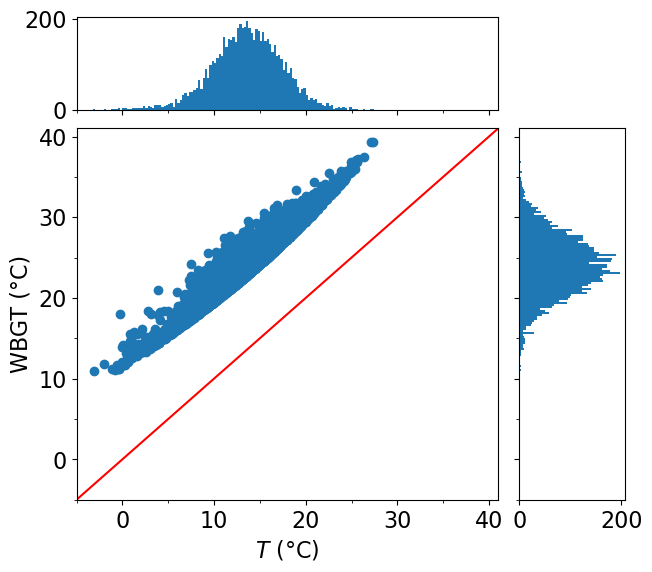

In [13]:
# Plot temperature (x-axis) and WBGT (y-axis) of flagged values

set_fontsize = 16
plt.rcParams.update({'font.size': 10,
                    'axes.labelsize':set_fontsize, # Axes labels
                    'xtick.labelsize':set_fontsize,
                    'ytick.labelsize':set_fontsize})

fig = plt.figure(layout='constrained', figsize=(6.4, 5.6))
ax = fig.add_subplot()

var_x = tas_array_diff_wind
var_y = wbgt_array_diff_wind

ax_histx = ax.inset_axes([0, 1.05, 1, 0.25], sharex=ax)
ax_histy = ax.inset_axes([1.05, 0, 0.25, 1], sharey=ax)

scatter_hist(var_x, var_y, ax, ax_histx, ax_histy)

set_xmin = np.floor(np.nanmin(var_x)) - 1
set_xmax = np.ceil(np.nanmax(var_x)) + 1
set_ymin = np.floor(np.nanmin(var_y)) - 1
set_ymax = np.ceil(np.nanmax(var_y)) + 1

plt.plot([np.min([set_xmin,set_ymin]),np.max([set_xmax,set_ymax])],[np.min([set_xmin,set_ymin]),np.max([set_xmax,set_ymax])], 'r')

plt.xlim([np.min([set_xmin,set_ymin]),np.max([set_xmax,set_ymax])])
plt.ylim([np.min([set_xmin,set_ymin]),np.max([set_xmax,set_ymax])])

plt.xlabel('$\it{T}$ (\N{degree sign}C)')
plt.ylabel('WBGT (\N{degree sign}C)')

ax.xaxis.set_major_locator(MultipleLocator(10)) # Major ticks
ax.xaxis.set_minor_locator(MultipleLocator(5)) # Minor ticks
ax.yaxis.set_major_locator(MultipleLocator(10)) # Major ticks
ax.yaxis.set_minor_locator(MultipleLocator(5)) # Minor ticks



Text(0, 0.5, 'WBGT minus $\\it{T}$ (°C)')

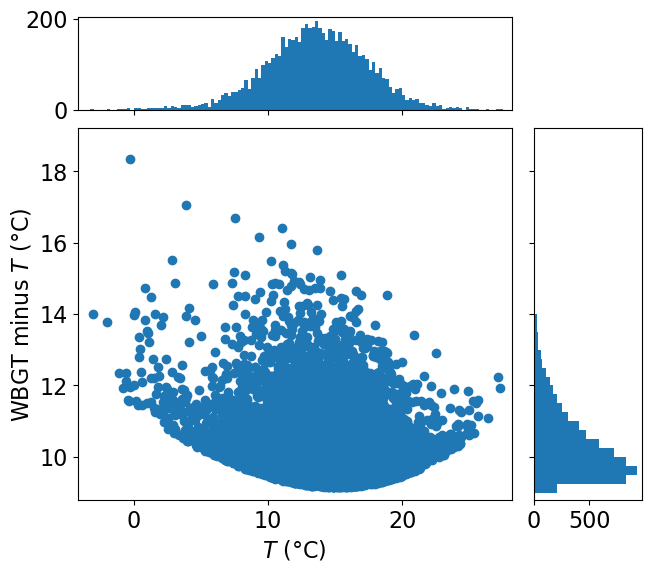

In [14]:
# Plot temperature (x-axis) and WBGT minus temperature (y-axis) of flagged values
# This figure is not used in the report

fig = plt.figure(layout='constrained', figsize=(6.4, 5.6))
ax = fig.add_subplot()

var_x = tas_array_diff_wind
var_y = wbgt_array_diff_wind - tas_array_diff_wind

ax_histx = ax.inset_axes([0, 1.05, 1, 0.25], sharex=ax)
ax_histy = ax.inset_axes([1.05, 0, 0.25, 1], sharey=ax)

scatter_hist(var_x, var_y, ax, ax_histx, ax_histy)

min_max_buffer = 0.2
set_xmin = np.floor(np.nanmin(var_x)) - min_max_buffer
set_xmax = np.ceil(np.nanmax(var_x)) + min_max_buffer
set_ymin = np.floor(np.nanmin(var_y)) - min_max_buffer
set_ymax = np.ceil(np.nanmax(var_y)) + min_max_buffer

plt.xlim([set_xmin,set_xmax])
plt.ylim([set_ymin,set_ymax])

plt.xlabel('$\it{T}$ (\N{degree sign}C)')
plt.ylabel('WBGT minus $\it{T}$ (\N{degree sign}C)')


Text(0, 0.5, 'WBGT (°C)')

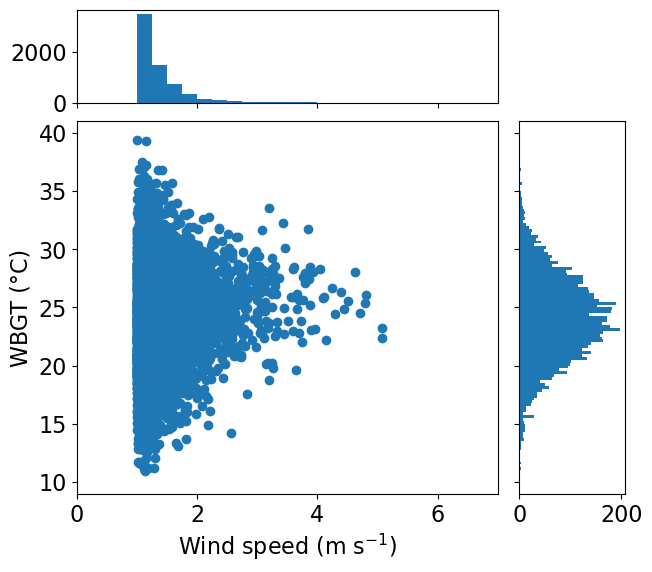

In [15]:
# Plot wind speed (x-axis) and WBGT (y-axis) of flagged values
# This figure is not used in the report

fig = plt.figure(layout='constrained', figsize=(6.4, 5.6))
ax = fig.add_subplot()

var_x = sfcWind_array_diff_wind
var_y = wbgt_array_diff_wind

ax_histx = ax.inset_axes([0, 1.05, 1, 0.25], sharex=ax)
ax_histy = ax.inset_axes([1.05, 0, 0.25, 1], sharey=ax)

scatter_hist(var_x, var_y, ax, ax_histx, ax_histy)


set_xmin = np.floor(np.nanmin(var_x)) - 1
set_xmax = np.ceil(np.nanmax(var_x)) + 1
set_ymin = np.floor(np.nanmin(var_y)) - 1
set_ymax = np.ceil(np.nanmax(var_y)) + 1


plt.xlim([set_xmin,set_xmax])
plt.ylim([set_ymin,set_ymax])

plt.xlabel(wind_label)
plt.ylabel('WBGT (\N{degree sign}C)')


Text(0, 0.5, 'WBGT minus $\\it{T}$ (°C)')

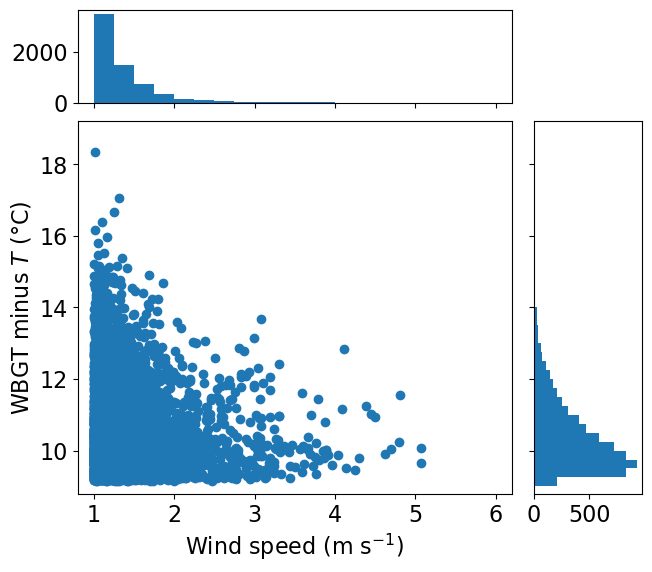

In [16]:
# Plot wind speed (x-axis) and WBGT minus temperature (y-axis) of flagged values
# This figure is not used in the report

fig = plt.figure(layout='constrained', figsize=(6.4, 5.6))
ax = fig.add_subplot()

var_x = sfcWind_array_diff_wind
var_y = wbgt_array_diff_wind - tas_array_diff_wind

ax_histx = ax.inset_axes([0, 1.05, 1, 0.25], sharex=ax)
ax_histy = ax.inset_axes([1.05, 0, 0.25, 1], sharey=ax)

scatter_hist(var_x, var_y, ax, ax_histx, ax_histy)

min_max_buffer = 0.2
set_xmin = np.floor(np.nanmin(var_x)) - min_max_buffer
set_xmax = np.ceil(np.nanmax(var_x)) + min_max_buffer
set_ymin = np.floor(np.nanmin(var_y)) - min_max_buffer
set_ymax = np.ceil(np.nanmax(var_y)) + min_max_buffer


plt.xlim([set_xmin,set_xmax])
plt.ylim([set_ymin,set_ymax])

plt.xlabel(wind_label)
plt.ylabel('WBGT minus $\it{T}$ (\N{degree sign}C)')


Text(0, 0.5, 'WBGT minus $\\it{T}$ minus curve (°C)')

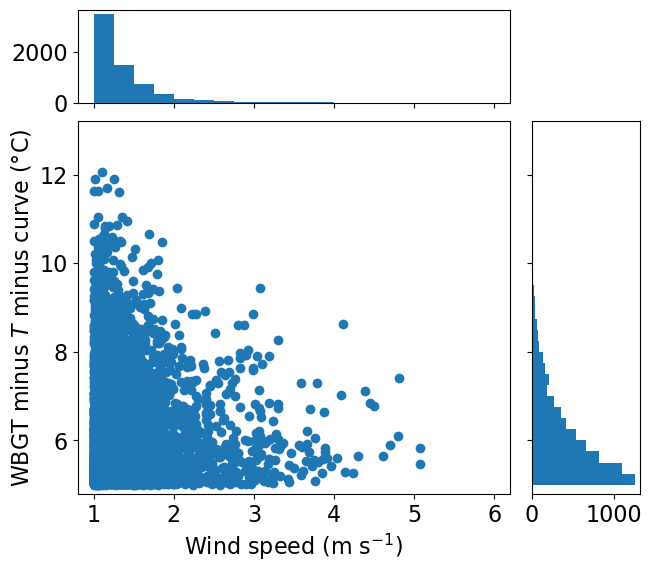

In [17]:
# Plot wind speed (x-axis) and WBGT minus temperature minus curve (y-axis) of flagged values
# This figure is not used in the report

fig = plt.figure(layout='constrained', figsize=(6.4, 5.6))
ax = fig.add_subplot()

var_x = sfcWind_array_diff_wind
var_y = wbgt_array_diff_wind - tas_array_diff_wind - curve_array_diff_wind

ax_histx = ax.inset_axes([0, 1.05, 1, 0.25], sharex=ax)
ax_histy = ax.inset_axes([1.05, 0, 0.25, 1], sharey=ax)

scatter_hist(var_x, var_y, ax, ax_histx, ax_histy)

min_max_buffer = 0.2
set_xmin = np.floor(np.nanmin(var_x)) - min_max_buffer
set_xmax = np.ceil(np.nanmax(var_x)) + min_max_buffer
set_ymin = np.floor(np.nanmin(var_y)) - min_max_buffer
set_ymax = np.ceil(np.nanmax(var_y)) + min_max_buffer


plt.xlim([set_xmin,set_xmax])
plt.ylim([set_ymin,set_ymax])

plt.xlabel(wind_label)
plt.ylabel('WBGT minus $\it{T}$ minus curve (\N{degree sign}C)')


In [18]:
time_array_diff_wind_unique = np.unique(time_array_diff_wind)

time_array_diff_wind_unique_year = np.zeros(len(time_array_diff_wind_unique)) * np.nan
time_array_diff_wind_unique_count = np.zeros(len(time_array_diff_wind_unique))

for i in np.arange(len(time_array_diff_wind_unique)):
    time_array_diff_wind_unique_count[i] = np.sum(time_array_diff_wind == time_array_diff_wind_unique[i])


Text(0, 0.5, 'Count per hour')

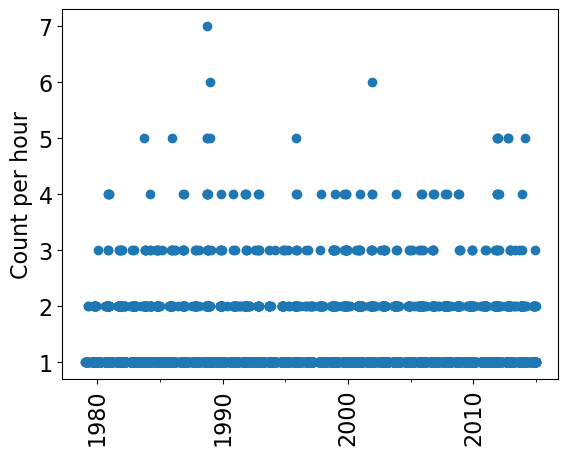

In [19]:
# Plot number of flagged values per time step (hour)

set_fontsize = 16
plt.rcParams.update({'font.size': 10,
                    'axes.labelsize':set_fontsize, # Axes labels
                    'xtick.labelsize':set_fontsize,
                    'ytick.labelsize':set_fontsize})

fig, ax = plt.subplots()

ax.scatter(time_array_diff_wind_unique,time_array_diff_wind_unique_count)

locator = mdates.YearLocator(10, month=1, day=1)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
locator_minor = mdates.YearLocator(5, month=1, day=1)
ax.xaxis.set_minor_locator(locator_minor)

plt.xticks(rotation=90)

if np.nanmax(time_array_diff_wind_unique_count) <= 10:
    ax.yaxis.set_major_locator(MultipleLocator(1)) # Major ticks
    ax.yaxis.set_minor_locator(MultipleLocator(1)) # Minor ticks
elif np.nanmax(time_array_diff_wind_unique_count) <= 20:
    ax.yaxis.set_major_locator(MultipleLocator(2)) # Major ticks
    ax.yaxis.set_minor_locator(MultipleLocator(1)) # Minor ticks
elif np.nanmax(time_array_diff_wind_unique_count) <= 100:
    ax.yaxis.set_major_locator(MultipleLocator(10)) # Major ticks
    ax.yaxis.set_minor_locator(MultipleLocator(5)) # Minor ticks
elif np.nanmax(time_array_diff_wind_unique_count) > 100:
    ax.yaxis.set_major_locator(MultipleLocator(100)) # Major ticks
    ax.yaxis.set_minor_locator(MultipleLocator(50)) # Minor ticks
    
plt.ylabel('Count per hour')
